Model type is CLIP (Contrastive Language-Image Pretraining), which maps text and images to a shared vector space.

Questions:

- What is the vector size produced by clip-ViT-B-32?
    - Model clip-ViT-B-32 generates vector size = 512

- What do ViT, B and 32 mean in the model name?
    - ViT (Vision Transformer) - it's an architecture based on transformers, which splits the image into smaller pieces (patches), which are treated similarly to tokens.
    - B (Base) - model scale/size
    -32 - patch size - 32 x 32 pixels. A larger patch size means fewer tokens and a faster model, but at the cost of less details.

In [3]:
from pgvector.sqlalchemy import Vector
from sqlalchemy import String, create_engine
from sqlalchemy.engine import URL
from sqlalchemy.orm import DeclarativeBase, Mapped, Session, mapped_column

db_url = URL.create(
    drivername="postgresql+psycopg",
    username="postgres",
    password="password",
    host="localhost",
    port=5555,
    database="similarity_search_service_db",
)
engine = create_engine(db_url)

In [ ]:
class Base(DeclarativeBase):
    __abstract__ = True


class Images(Base):
    __tablename__ = "images"
    __table_args__ = {"extend_existing": True}
    VECTOR_LENGTH: int = 512

    id: Mapped[int] = mapped_column(primary_key=True)
    image_path: Mapped[str] = mapped_column(String(512))  # implement me!
    embedding: Mapped[list[float]] = mapped_column(
        Vector(VECTOR_LENGTH)
    )  # implement me!


# Create table
Base.metadata.drop_all(engine)
Base.metadata.create_all(engine)

In [7]:
import torch
from sentence_transformers import SentenceTransformer

device = "cuda" if torch.cuda.is_available() else "cpu"
model = SentenceTransformer("clip-ViT-B-32", device=device)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

In [8]:
import joblib
import torch
from PIL import Image
from sentence_transformers import SentenceTransformer
from tqdm.notebook import tqdm
from itertools import batched
from extract_paths import get_image_paths


MAX_IMAGES = 1000  # Adjust it for your needs
BATCH_SIZE = joblib.cpu_count(only_physical_cores=True)

image_paths = get_image_paths()[:MAX_IMAGES]


def insert_images(engine, images):
    with Session(engine) as session:
        session.add_all(images)
        session.commit()


def vectorize_images(engine, model, image_paths):
    with tqdm(total=MAX_IMAGES) as pbar:
        for images_paths_batch in batched(
            image_paths, BATCH_SIZE
        ):  # finish (suggestion - use `batched`)
            images = [Image.open(path) for path in images_paths_batch]

            # calculate embeddings
            embeddings = model.encode(images)

            # create Img instances for all images in batch
            imgs = []
            for path, embedding in zip(images_paths_batch, embeddings):
                imgs.append(Images(image_path=path, embedding=embedding.tolist()))

            # insert all batch images
            insert_images(engine, imgs)

            # update pbar
            pbar.update(len(imgs))


vectorize_images(engine, model, image_paths)

  0%|          | 0/1000 [00:00<?, ?it/s]

In [15]:
import matplotlib.pyplot as plt
from sqlalchemy import select


class ImageSearch:
    def __init__(self, engine, model):
        self.engine = engine
        self.model = model

    def __call__(self, image_description: str, k: int):
        found_images = self.find_similar_images(image_description, k)
        # display images
        self.display_images(found_images)

    def find_similar_images(self, image_description: str, k: int):
        image_embedding = self.model.encode(
            image_description
        ).tolist()  # calculate embedding of image_description

        # remember about session and commit
        query = (
            # write query to find K images with highest cosine distance
            select(Images.image_path)
            .order_by(Images.embedding.cosine_distance(image_embedding))
            .limit(k)
        )
        with Session(self.engine) as session:
            result = session.execute(query).scalars().all()  # execute query
        return result

    def display_images(self, images):

        k = len(images)
        fig, axes = plt.subplots(1, k, figsize=(15, 5))

        for i, img_path in enumerate(images):
            img = Image.open(img_path)
            axes[i].imshow(img)
            axes[i].axis("off")
            axes[i].set_title(f"Image {i + 1}")

        plt.show()

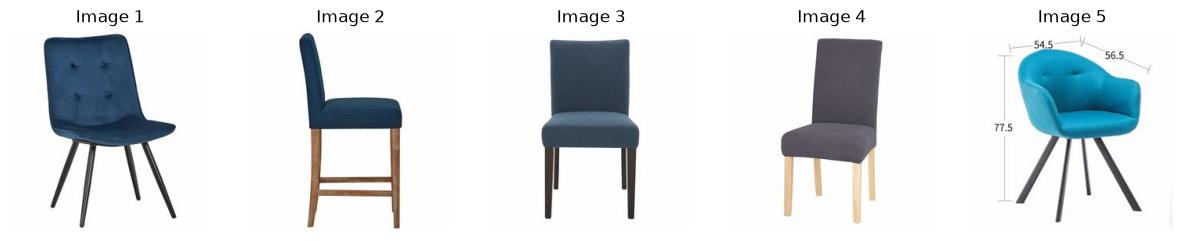

In [18]:
search = ImageSearch(engine, model)
search("a blue chair", k=5)

Wszystkie 5 wyników to krzesła, z tym że czwarte jest raczej szare niż niebieskie.

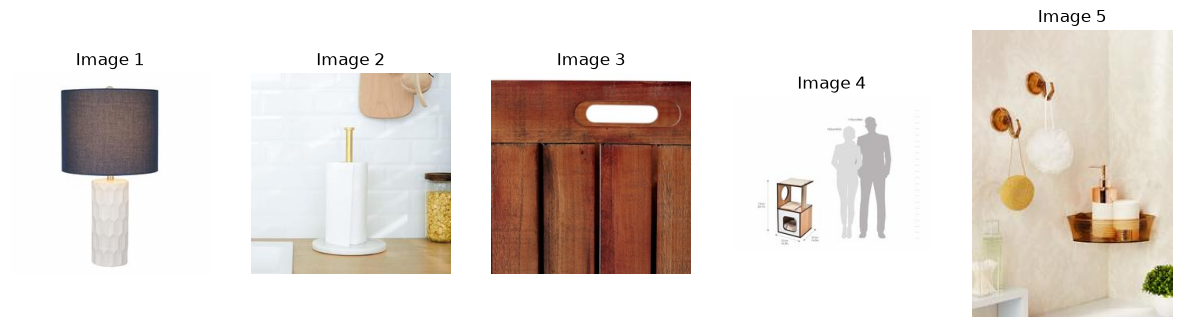

In [ ]:
search("a wooden lamp", k=5)

Niezbyt dobre wyszukiwanie - tylko jeden wynik jest lampą i nie jest drewniana. Część zwróconych obrazów posiada elementy drewniane. Być może w zbiorze nie było drewnianej lampy więc zostało zwrócone najbliższe co było. 

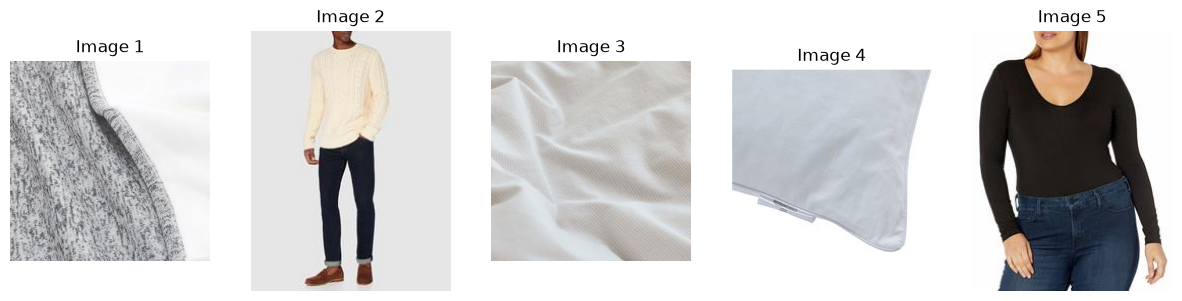

In [ ]:
search("a longsleeve shirt", k=5)

Średni wynik - wszystkie z nich pokazują materiały, ale tylko dwa to bluzki z długim rękawem.

2000


  0%|          | 0/2000 [00:00<?, ?it/s]

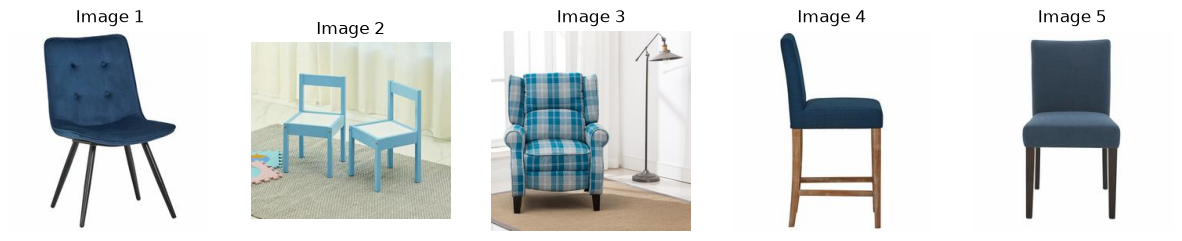

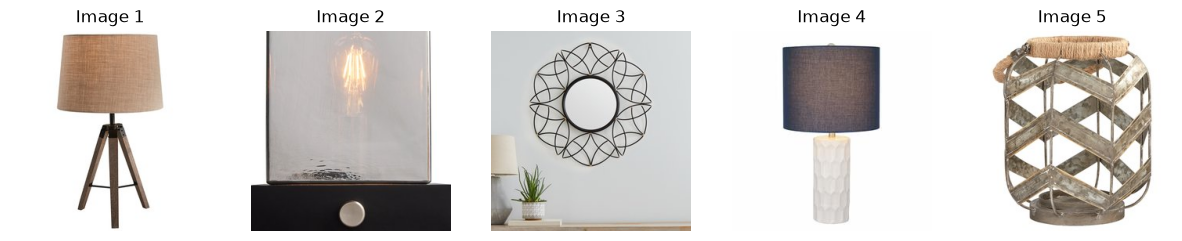

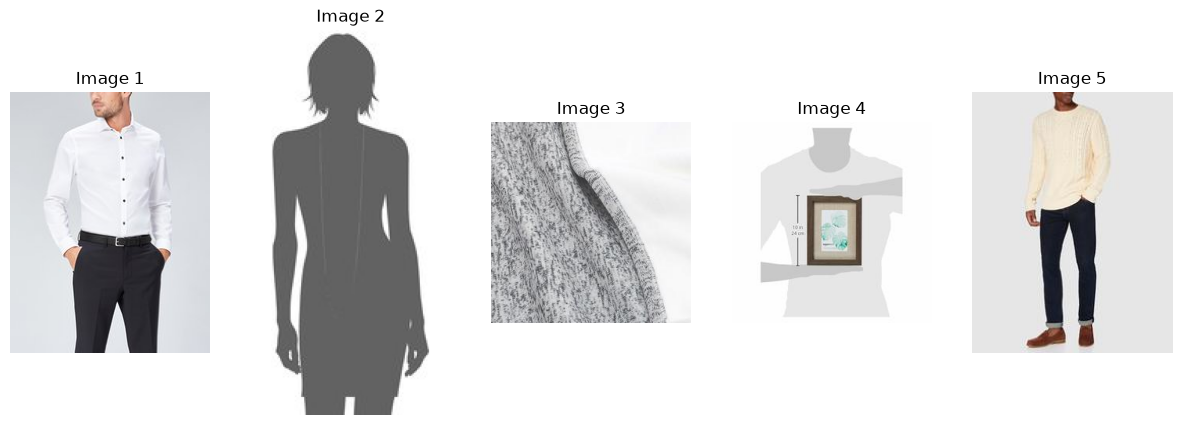

In [24]:
Base.metadata.drop_all(engine)
Base.metadata.create_all(engine)

MAX_IMAGES = 2000
all_paths = get_image_paths()
image_paths = all_paths[:MAX_IMAGES]
print(len(image_paths))
vectorize_images(engine, model, image_paths)

search = ImageSearch(engine, model)
search("a blue chair", k=5)
search("a wooden lamp", k=5)
search("a longsleeve shirt", k=5)

500


  0%|          | 0/500 [00:00<?, ?it/s]

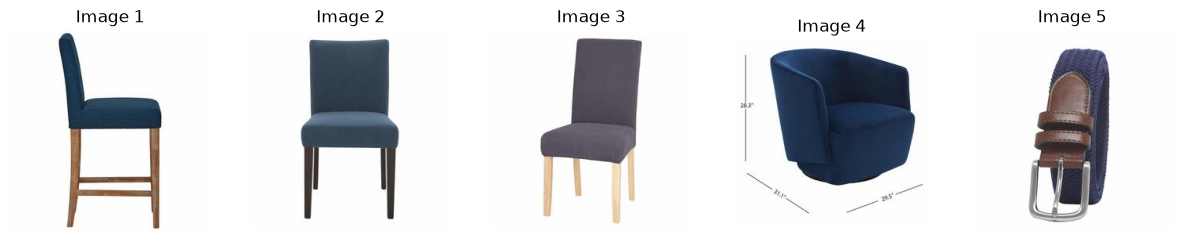

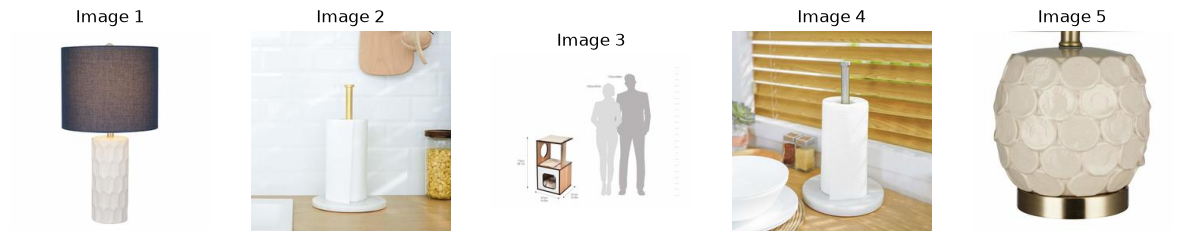

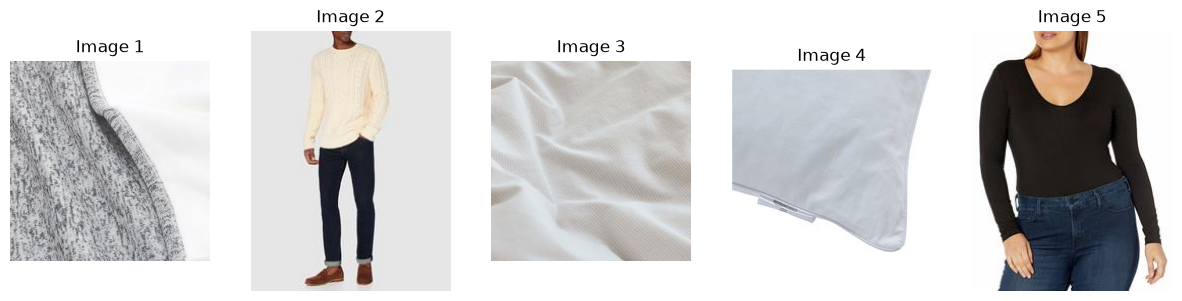

In [25]:
Base.metadata.drop_all(engine)
Base.metadata.create_all(engine)

MAX_IMAGES = 500
all_paths = get_image_paths()
image_paths = all_paths[:MAX_IMAGES]
print(len(image_paths))
vectorize_images(engine, model, image_paths)

search = ImageSearch(engine, model)
search("a blue chair", k=5)
search("a wooden lamp", k=5)
search("a longsleeve shirt", k=5)

6000


  0%|          | 0/6000 [00:00<?, ?it/s]

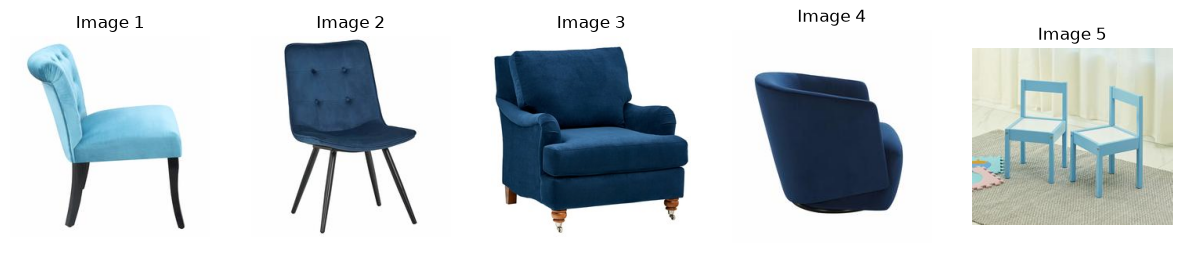

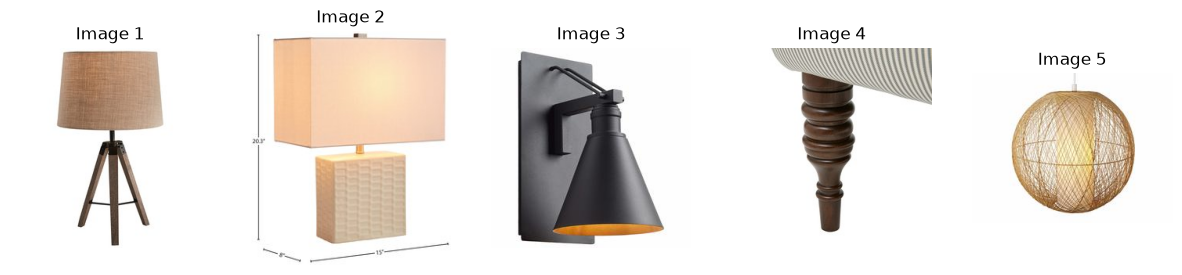

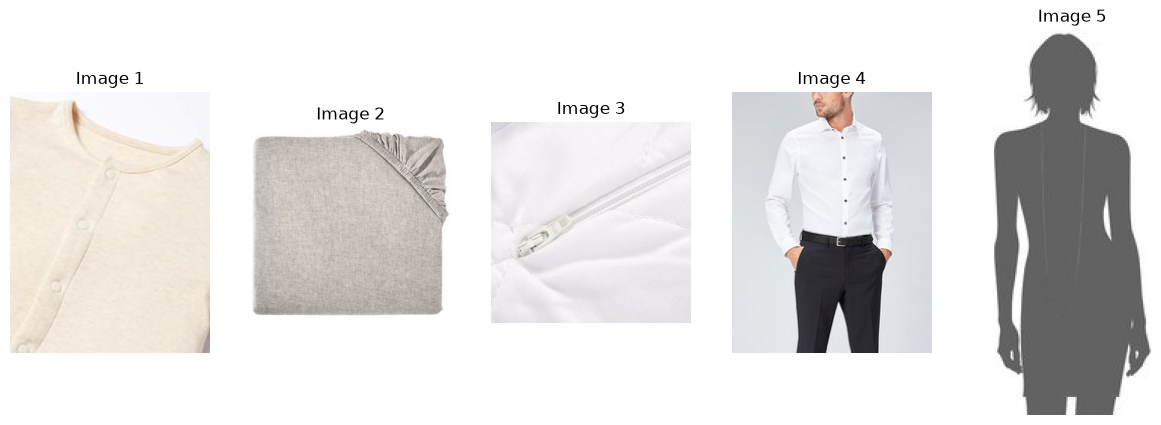

In [26]:
Base.metadata.drop_all(engine)
Base.metadata.create_all(engine)

MAX_IMAGES = 6000
all_paths = get_image_paths()
image_paths = all_paths[:MAX_IMAGES]
print(len(image_paths))
vectorize_images(engine, model, image_paths)

search = ImageSearch(engine, model)
search("a blue chair", k=5)
search("a wooden lamp", k=5)
search("a longsleeve shirt", k=5)

Check 3 different MAX_IMAGES sizes. Do you see more accurate results for larger datasets?

Większy zbiór poprawia wyniki, zwłaszcza dla rzadszych obiektów (np. drewniana lampa), bo rośnie szansa, że w bazie jest pasujący obraz. Dla częstych obiektów (np. krzesło) poprawa jest niewielka, a dla zapytania o koszulę z długim rękawem jej nie było. Przy małym zbiorze model często zwracał rzeczy podobne kolorem lub materiałem, ale nie kategorią (np pasek zamiast krzesła). Dla zapytania  "a longsleeve shirt" większy zbiór nie pomógł, bo prawdopodobnie w zbiorze  dominują tekstylia, więc model dopasowuje je semantycznie do "ubrania”. Wniosek jest taki, że więcej danych pomaga, o ile w zbiorze są pasujące do zapytania obrazy.